In [1]:
import pandas as pd

df = pd.read_csv('dabba_dash_orders.csv')
df.head()

,order_id,order_date,order_time,city,cuisine,customer_type,payment_method,order_value_inr,discount_pct,delivery_fee_inr,distance_km,delivery_time_min,rating,status
0,DD102118,24-10-2025,19:46,Bengaluru,Desserts,New,UPI,261.0,40,29.0,3.4,28.0,5.0,Delivered
1,DD103878,18-06-2026,19:27,Thane,Chinese,New,UPI,413.0,25,20.0,1.2,20.0,NaN,Delivered
2,DD100265,07-03-2025,11:45,Mumbai,Pizza,Returning,UPI,160.0,0,22.0,1.7,11.0,4.0,Delivered
3,DD108000,11-06-2026,16:31,Pune,Burgers,Returning,Card,242.0,0,18.0,0.8,11.0,5.0,Delivered
4,DD100380,22-04-2025,23:30,Pune,South Indian,Returning,UPI,340.0,15,28.0,3.2,16.0,NaN,Delivered


In [2]:
df.shape

(15180, 14)

In [3]:
df.dtypes

order_id              object
order_date            object
order_time            object
city                  object
cuisine               object
customer_type         object
payment_method        object
order_value_inr      float64
discount_pct           int64
delivery_fee_inr     float64
distance_km          float64
delivery_time_min    float64
rating               float64
status                object
dtype: object

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15180 entries, 0 to 15179
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           15180 non-null  object 
 1   order_date         15180 non-null  object 
 2   order_time         15180 non-null  object 
 3   city               15180 non-null  object 
 4   cuisine            15180 non-null  object 
 5   customer_type      14859 non-null  object 
 6   payment_method     14951 non-null  object 
 7   order_value_inr    15180 non-null  float64
 8   discount_pct       15180 non-null  int64  
 9   delivery_fee_inr   15180 non-null  float64
 10  distance_km        15180 non-null  float64
 11  delivery_time_min  14339 non-null  float64
 12  rating             8885 non-null   float64
 13  status             15180 non-null  object 
dtypes: float64(5), int64(1), object(8)
memory usage: 1.6+ MB


In [5]:
df.describe()

,order_value_inr,discount_pct,delivery_fee_inr,distance_km,delivery_time_min,rating
count,15180.000000,15180.000000,15180.000000,15180.000000,14339.000000,8885.000000
mean,421.547101,9.021739,22.624967,3.085455,27.188995,4.371187
std,224.094367,10.106237,12.745839,2.054965,28.258012,0.661529
min,60.000000,0.000000,0.000000,0.300000,8.000000,2.000000
25%,264.000000,0.000000,19.000000,1.600000,20.000000,4.000000
50%,375.000000,5.000000,24.000000,2.600000,25.000000,4.000000
75%,525.000000,15.000000,30.000000,4.100000,30.000000,5.000000
max,2773.000000,40.000000,63.000000,12.000000,699.000000,5.000000


In [6]:
df.isnull().sum()

order_id                0
order_date              0
order_time              0
city                    0
cuisine                 0
customer_type         321
payment_method        229
order_value_inr         0
discount_pct            0
delivery_fee_inr        0
distance_km             0
delivery_time_min     841
rating               6295
status                  0
dtype: int64

In [7]:
df['city'].value_counts()

city
Mumbai        4154
Bengaluru     3203
Delhi         2504
Pune          1785
Hyderabad     1668
Thane         1070
mumbai         178
New Delhi      171
BENGALURU      170
Bangalore      139
bengaluru      138
Name: count, dtype: int64

In [8]:
df.duplicated().sum()

np.int64(180)

In [9]:
df[df['delivery_time_min'].isnull()]['status'].value_counts()

status
Cancelled    841
Name: count, dtype: int64

In [10]:
df[df['rating'].isnull()]['status'].value_counts()

status
Delivered    5454
Cancelled     841
Name: count, dtype: int64

In [11]:
df['city'] = df['city'].str.strip()

city_fix = {
    'mumbai': 'Mumbai',
    'New Delhi': 'Delhi',
    'BENGALURU': 'Bengaluru',
    'Bangalore': 'Bengaluru',
    'bengaluru': 'Bengaluru',
}
df['city'] = df['city'].replace(city_fix)

df['city'].value_counts()

city
Mumbai       4332
Bengaluru    3650
Delhi        2675
Pune         1785
Hyderabad    1668
Thane        1070
Name: count, dtype: int64

In [12]:
df = df.drop_duplicates()
df.shape

(15000, 14)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
slow = df[df['delivery_time_min'] > 180]
print(len(slow))
slow[['order_id', 'distance_km', 'delivery_time_min', 'status']].head(10)

49


,order_id,distance_km,delivery_time_min,status
434,DD101436,1.7,403.0,Delivered
754,DD101170,3.6,279.0,Delivered
1145,DD110990,4.1,646.0,Delivered
1413,DD103637,0.7,660.0,Delivered
1417,DD113086,1.1,643.0,Delivered
1581,DD105706,5.2,387.0,Delivered
2083,DD105012,4.6,434.0,Delivered
2437,DD103317,2.2,319.0,Delivered
2480,DD112941,0.9,489.0,Delivered
2804,DD102080,3.4,315.0,Delivered


In [15]:
df['delivery_time_min'].mean()

np.float64(27.197487295313383)

In [16]:
df[df['delivery_time_min'] <= 180]['delivery_time_min'].mean()

np.float64(25.655287201643176)

In [17]:
before = df['delivery_time_min'].isnull().sum()

df['delivery_time_min'] = df['delivery_time_min'].where(df['delivery_time_min'] <= 180)

after = df['delivery_time_min'].isnull().sum()
print(before, after)

832 881


In [18]:
df['delivery_time_min'].mean()

np.float64(25.655287201643176)

In [19]:
df.shape

(15000, 14)

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df['order_date'] = pd.to_datetime(df['order_date'], format='%d-%m-%Y')
df['month'] = df['order_date'].dt.strftime('%Y-%m')
df[['order_date', 'month']].head()

,order_date,month
0,2025-10-24,2025-10
1,2026-06-18,2026-06
2,2025-03-07,2025-03
3,2026-06-11,2026-06
4,2025-04-22,2025-04


In [22]:
df['month'].nunique()

18

In [23]:
print(df['customer_type'].isnull().sum(), df['payment_method'].isnull().sum())
print(df['customer_type'].value_counts())

317 227
customer_type
Returning    9564
New          5119
Name: count, dtype: int64


## Cleaning decisions

1. **City names:** The city column had 11 spellings for 6 real cities (e.g. "mumbai", "New Delhi", "Bangalore", "BENGALURU"). I stripped extra spaces and mapped every variant to one standard name, which changed 796 rows. Left alone, each spelling would have shown up as a separate city in every chart.
2. **Duplicates:** 180 rows were exact copies of other rows. I removed them (15,180 to 15,000 rows). Keeping them would have double-counted those orders and inflated revenue and order counts.
3. **Impossible delivery times:** 49 delivered orders had delivery times of 180+ minutes, far beyond anything realistic and most likely clock errors. I blanked those values instead of dropping the rows, so the orders still count toward revenue. This moved the average delivery time from 27.2 to 25.7 minutes.
4. **Blank delivery_time / rating:** I left these blank on purpose. Cancelled orders (832 after removing duplicates) were never delivered, so they have no delivery time, and many delivered orders were simply never rated. Filling them with an average would invent data that never existed. Pandas skips blanks when averaging, so they do not distort the results.
5. **Blank customer_type / payment_method:** 317 and 227 rows (about 2% and 1.5% of orders). I left them blank because the true value is unknown and guessing would add false data. These rows drop out of any grouping by customer type or payment method, so those totals add up to slightly less than 15,000. I state the denominator whenever I show a percentage.

In [24]:
delivered = df[df['status'] == 'Delivered']
len(delivered)

14168

In [25]:
city_revenue = delivered.groupby('city')['order_value_inr'].sum().sort_values(ascending=False)
city_revenue

city
Mumbai       1853938.0
Bengaluru    1401347.0
Delhi        1081290.0
Pune          654349.0
Hyderabad     605039.0
Thane         373753.0
Name: order_value_inr, dtype: float64

In [26]:
share = (city_revenue / city_revenue.sum() * 100).round(1)
share

city
Mumbai       31.1
Bengaluru    23.5
Delhi        18.1
Pune         11.0
Hyderabad    10.1
Thane         6.3
Name: order_value_inr, dtype: float64

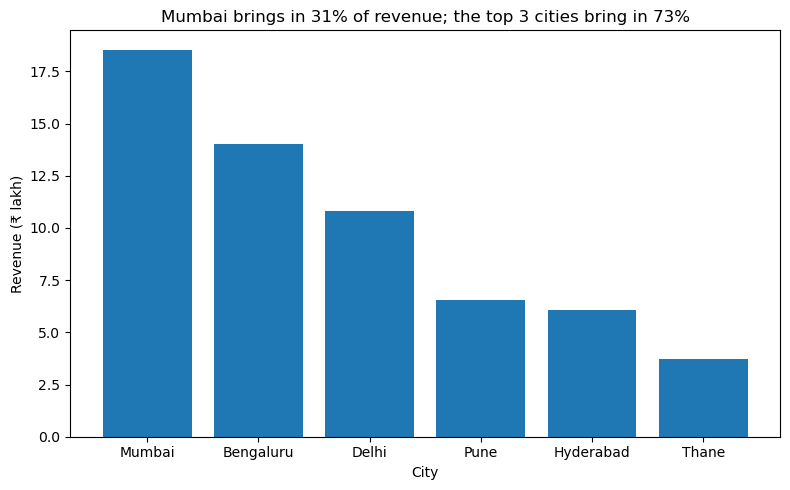

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(city_revenue.index, city_revenue.values / 100000)
plt.title('Mumbai brings in 31% of revenue; the top 3 cities bring in 73%')
plt.xlabel('City')
plt.ylabel('Revenue (₹ lakh)')
plt.tight_layout()
plt.savefig('revenue_by_city.png', dpi=150)
plt.show()

In [29]:
monthly_orders = df.groupby('month')['order_id'].count()
monthly_orders

month
2025-01     581
2025-02     559
2025-03     651
2025-04     664
2025-05     657
2025-06     754
2025-07     743
2025-08     761
2025-09     809
2025-10    1163
2025-11     931
2025-12     862
2026-01     950
2026-02     886
2026-03     945
2026-04     941
2026-05    1051
2026-06    1092
Name: order_id, dtype: int64

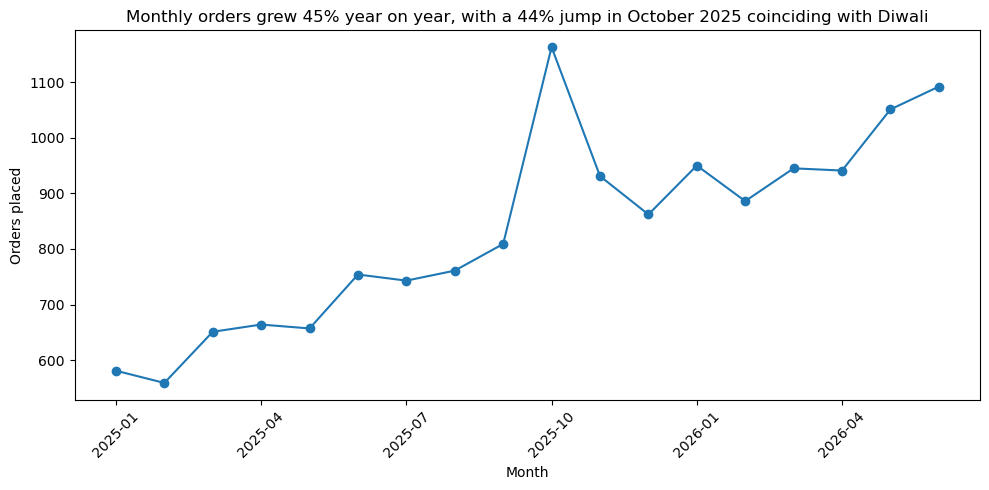

In [32]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_orders.index, monthly_orders.values, marker='o')
plt.xticks(monthly_orders.index[::3], rotation=45)
plt.title('Monthly orders grew 45% year on year, with a 44% jump in October 2025 coinciding with Diwali')
plt.xlabel('Month')
plt.ylabel('Orders placed')
plt.tight_layout()
plt.savefig('monthly_orders.png', dpi=150)
plt.show()

In [33]:
cancel_rate = (df.groupby('payment_method')['status'].apply(lambda s: (s == 'Cancelled').mean()) * 100).round(1)
cancel_rate.sort_values(ascending=False)

payment_method
COD       9.8
Card      4.7
UPI       4.7
Wallet    3.9
Name: status, dtype: float64

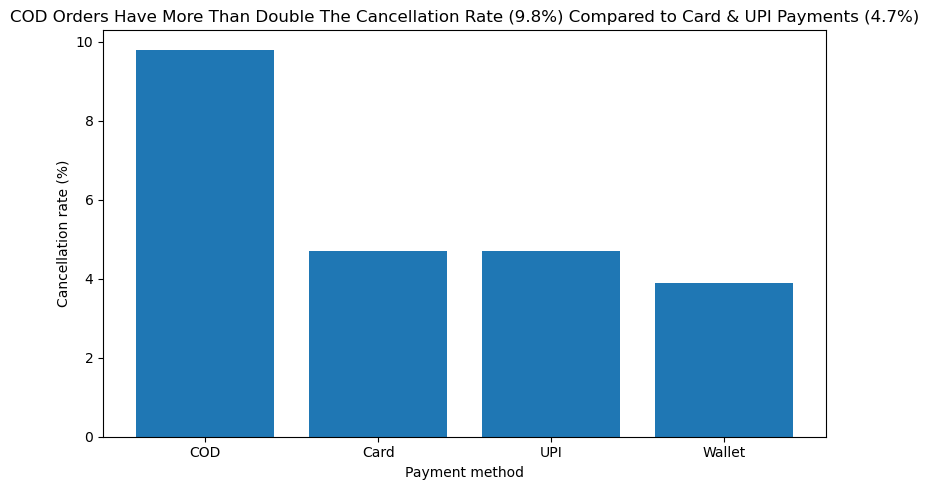

In [36]:
cancel_sorted = cancel_rate.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(cancel_sorted.index, cancel_sorted.values)
plt.title('COD Orders Have More Than Double The Cancellation Rate (9.8%) Compared to Card & UPI Payments (4.7%)')
plt.xlabel('Payment method')
plt.ylabel('Cancellation rate (%)')
plt.tight_layout()
plt.savefig('cancel_rate_by_payment.png', dpi=150)
plt.show()

                   distance_km  delivery_time_min
distance_km           1.000000           0.797322
delivery_time_min     0.797322           1.000000


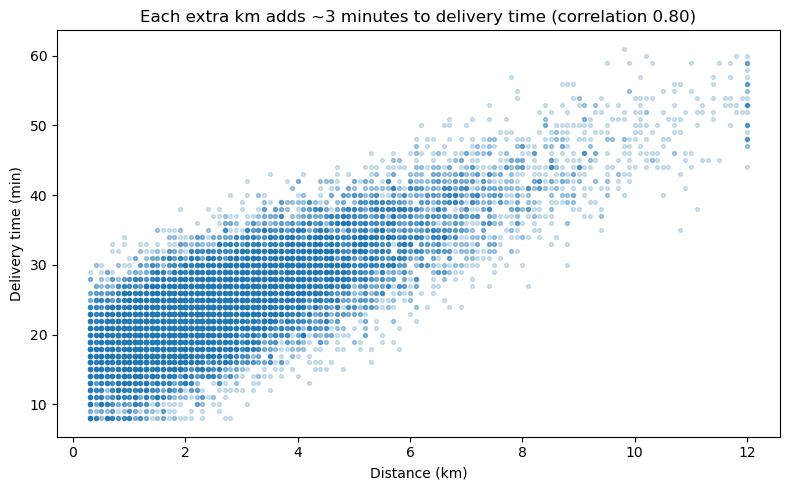

In [39]:
print(df[['distance_km', 'delivery_time_min']].corr())

plt.figure(figsize=(8, 5))
plt.scatter(df['distance_km'], df['delivery_time_min'], alpha=0.2, s=8)
plt.title('Each extra km adds ~3 minutes to delivery time (correlation 0.80)')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery time (min)')
plt.tight_layout()
plt.savefig('distance_vs_delivery_time.png', dpi=150)
plt.show()

In [40]:
import numpy as np

valid = df.dropna(subset=['delivery_time_min'])
slope, intercept = np.polyfit(valid['distance_km'], valid['delivery_time_min'], 1)
print(slope, intercept, len(valid))

3.1854480796469327 15.819880654485322 14119


In [41]:
valid = df.dropna(subset=['delivery_time_min'])
(valid['distance_km'] > 5).mean() * 100

np.float64(15.603088037396414)

## Summary

### Findings
1. **Revenue is concentrated in a few cities.** Mumbai brings in 31% of revenue, and the top 3 cities (Mumbai, Bengaluru, Delhi) bring in 73%.
2. **Orders are growing, with a festive spike.** Orders in June 2026 were 45% higher than in June 2025. October 2025 jumped 44% on September, coinciding with Diwali, then fell back about 20% in November, though still above pre-Diwali levels.
3. **COD orders cancel far more often.** COD orders have a 9.8% cancellation rate, more than double Card and UPI (4.7%).

### Recommendations
1. Because COD orders have more than double the cancellation rate of Card and UPI orders (9.8% vs 4.7%), run a limited promo for UPI and Card payments and see whether COD's share of orders and cancellations falls. (Caveat: the data shows COD orders cancel more, not that COD causes it, so a pilot is the right first step.)
2. Because each extra km adds about 3 minutes to delivery time, and about 1 in 6 delivered orders travel more than 5 km, we should prioritise restaurant partnerships closer to customers in areas where orders travel far, and test whether this brings delivery times down.